# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


<div class="alert alert-block alert-info">
¡Hola, Marcela! ¿Cómo va?<br><br>
Un gusto conocerte, soy Santiago yseré tu revisor en este proyecto. Te comparto la modalidad de revisión que vamos a usar:<br><br>
Cuando encuentre un error por primera vez, simplemente lo señalaré y dejaré que lo detectes y corrijas por tu cuenta. Además, a lo largo del proyecto iré haciendo algunas observaciones para mejorar tu código, así como comentarios sobre tus conclusiones.<br><br>
Si en algún momento no logras resolver la tarea, en la siguiente iteración te daré una pista más precisa, junto con algunos ejemplos prácticos. También estoy abierto a responder cualquier duda que tengas.<br><br>
Encontrarás mis comentarios a continuación: <b>por favor, no los muevas, modifiques ni elimines</b>.<br><br>
Puedes encontrar mis comentarios en cuadros verdes, amarillos o rojos como estos:
</div>

<div class="alert alert-block alert-success">
<b>Comentario del revisor.</b><br>Éxito. Todo se ha hecho de forma correcta.
</div>

<div class="alert alert-block alert-warning">
<b>Comentario del revisor.</b><br>Observación. Algunas recomendaciones o mejoras menores.
</div>

<div class="alert alert-block alert-danger">
<b>Comentario del revisor.</b><br>Necesita arreglos. Este apartado requiere algunas correcciones. El trabajo no puede ser aceptado con comentarios rojos.
</div>

<div class="alert alert-block alert-info">
Además verás cuadros azules 💡 con <b>tips de eficiencia</b> opcionales.<br><br>Puedes responder utilizando este formato:<br><br><b>Respuesta del estudiante.</b>
</div>

<div class="alert alert-block alert-danger">
<b>Review General. (Iteración 1)</b> <a class="tocSkip"></a><br><br>
Buenas, Marcela. Quería tomarme este momento al inicio de tu proyecto para comentarte mis apreciaciones generales sobre esta entrega.<br><br>
Antes que nada, ¡felicitaciones! Tu proyecto muestra un análisis muy cuidadoso: cuantificas cada problema con código, verificaste los datos de forma cruzada y detectaste por tu cuenta los 28 registros con <code>duration</code>/<code>length</code> que no corresponden a su tipo de actividad. Incluso construiste los minutos de llamada usando solo las llamadas. Eso es pensar como analista.<br><br>
<b>Resumen de tu proyecto por partes</b>
<ul>
<li><b>Parte 1. Carga y exploración ✅</b> — Rutas, variables y exploración con <code>head()</code>, <code>shape</code> e <code>info()</code> completas.</li>
<li><b>Parte 2. Calidad de datos ✅</b> — Diagnóstico de nulos muy completo, ambos sentinels cuantificados (55 y 96), <code>errors='coerce'</code> y conteo por año con los 40 registros de 2026.</li>
<li><b>Parte 3. Limpieza 🟡</b> — Fechas de 2026 bien marcadas. El <code>"?"</code> se reemplazó por el texto <code>"NA"</code> y no por un nulo, y en la conclusión MAR hay una confusión de conceptos.</li>
<li><b>Parte 4. Uso por usuario ✅</b> — Agregación, renombrado y <code>merge</code> con <code>how='left'</code> correctos.</li>
<li><b>Parte 5. Distribuciones y outliers ✅</b> — Histogramas por plan con insights detallados, y un análisis IQR con límites, cantidad y porcentaje de outliers.</li>
<li><b>Parte 6. Segmentación ✅</b> — Funciones claras que manejan los nulos y verificación con conteos y porcentajes.</li>
<li><b>Parte 7. Insight ejecutivo ❌</b> — Muy bien cuantificado y con conclusiones sólidas, pero falta responder las preguntas de <b>recomendaciones</b> y de <b>segmentos más valiosos</b>.</li>
<li><b>Parte 8. Publicación 🟡</b> — El link está en una celda de código.</li>
</ul>
<b>Estado de la entrega:</b> el proyecto está muy cerca, pero <b>aún no puede ser aceptado</b> por un único comentario rojo: en el <b>análisis ejecutivo</b> (paso 7) quedaron preguntas sin contestar. Ya tienes las ideas dispersas en tus insights, así que es cuestión de reunirlas. Los comentarios amarillos son recomendaciones para fortalecer tu trabajo.<br><br>
Espero con ansias tu próxima iteración. ¡Bien hecho!<br><br>Saludos.
</div>

--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [102]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Importaste las librerías en una sola celda al inicio. ¡Buena práctica!
</div>

In [103]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [104]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [105]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [106]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Datasets cargados con las rutas correctas, en las variables pedidas, y mostrados con <code>.head()</code> sin <code>print()</code>.
</div>

**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [107]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [108]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [109]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [110]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Exploración estructural completa con <code>.shape</code> etiquetado y <code>.info()</code> en los tres DataFrames.
</div>

---

## 🧩Paso 2: Identificación de problemas de calidad de datos
### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [111]:
# cantidad de nulos para users
print(users.isna().sum().sort_values(ascending=False)) # Cantidad de valores nulos
print()
print(users.isna().mean().sort_values(ascending=False)) # Proporción de valores nulos

churn_date    3534
city           469
user_id          0
first_name       0
last_name        0
age              0
reg_date         0
plan             0
dtype: int64

churn_date    0.88350
city          0.11725
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
reg_date      0.00000
plan          0.00000
dtype: float64


In [112]:
# cantidad de nulos para usage
print(usage.isna().sum().sort_values(ascending=False))
print()
print(usage.isna().mean().sort_values(ascending=False))

duration    22076
length      17896
date           50
id              0
user_id         0
type            0
dtype: int64

duration    0.55190
length      0.44740
date        0.00125
id          0.00000
user_id     0.00000
type        0.00000
dtype: float64


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Conteo y proporción de nulos en ambos datasets, ordenados de mayor a menor con <code>sort_values()</code>. Así lo más relevante queda arriba. ¡Muy bien!
</div>

**Diagnóstico de datos**

**DF_users**
- La columna **`churn_date`** presenta un 88.35% de valores nulos, lo que sugiere que el 11.65% de los usuarios ha cancelado su plan telefónico. Se recomienda conservar los nulos, ya que podrían representar usuarios activos.
- La columna **`city`** presenta un 11.72% de valores faltantes, lo que puede afectar el análisis demográfico. Se recomienda conservar los registros y clasificar los valores faltantes como "Desconocida", evitando asignar una ciudad sin evidencia.
- Es necesario convertir las columnas **`reg_date`** y **`churn_date`** al tipo de dato `datetime` para facilitar su análisis.

**DF_usage**
- Las columnas **`duration`** (55.19%) y **`length`** (44.74%) presentan valores nulos. Sin embargo, es necesario analizar su relación con la columna **`type`** para determinar si representan datos faltantes o si corresponden al tipo de actividad registrada (`call` o `text`). Por el momento, no se recomienda imputarlos.
- La columna **`date`** presenta un 0.12% de valores faltantes. Dada su baja proporción, se recomienda excluir estos registros de los análisis que requieran información temporal.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Diagnóstico de nulos muy completo! Cada columna tiene porcentaje, acción y justificación, y anticipas que los nulos de <code>duration</code>/<code>length</code> pueden depender de <code>type</code>. Muy buen criterio al conservar los registros de <code>city</code> sin inventar una ciudad.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Borra el texto de la plantilla ("Haz doble clic...", la Nota, el Hint y las preguntas) y deja solo tu diagnóstico.
</div>

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [113]:
# explorar columnas numéricas de users
cols_num_users = users[['user_id', 'age']]
print("user_id:", users['user_id'].nunique())
print()
print(cols_num_users.describe())
print()
print('sentinel_age:', users['age'].isin([-999]).sum())

user_id: 4000

            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000

sentinel_age: 55


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Muy bien contar el sentinel con código (<code>isin([-999]).sum()</code>) y verificar que <code>user_id</code> no tiene duplicados con <code>nunique()</code>.
</div>

- La columna `user_id` contiene 4,000 registros únicos y no nulos.
- La columna `age` presenta 55 valores *sentinel* (`-999`), equivalentes al 1.38% de los registros, los cuales distorsionan las estadísticas descriptivas, por lo que dada la cercanía entre la media y la mediana de las edades válidas, se recomienda imputarlos utilizando la mediana para no considerar los valores sentinel.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Excelente: cuantificas el sentinel (55, 1.38 %) y explicas cómo distorsiona las estadísticas.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Aquí recomiendas imputar con la <b>media</b>, pero en tu diagnóstico de sentinels y en el paso 3 se usa la <b>mediana</b>. Unifica el criterio: la mediana es más robusta frente a valores extremos y es lo que pide el paso 3.
</div>

In [114]:
# explorar columnas numéricas de usage
cols_num_usage = usage[['id', 'user_id', 'duration', 'length']]
print(cols_num_usage.nunique())
print()
print(cols_num_usage.describe())

id          40000
user_id      3999
duration     2090
length        123
dtype: int64

                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000


- Las columnas `id` y `user_id` contienen 40,000 registros no nulos. La primera presenta 40,000 valores únicos, lo que confirma que no hay identificadores de actividad duplicados. La segunda contiene 3,999 usuarios únicos, lo que indica que existen múltiples registros de actividad por usuario.

- Las columnas `duration` (17,924 registros no nulos) y `length` (22,104 registros no nulos) presentan valores faltantes que podrían estar relacionados con el tipo de actividad (`call` o `text`). Se recomienda verificar esta relación antes de realizar imputaciones.

- Las estadísticas descriptivas muestran posibles valores atípicos: `duration` presenta una mediana de 3.5 y un máximo de 120, mientras que `length` presenta una mediana de 50 y un máximo de 1,490. Se recomienda investigar estos valores mediante visualizaciones y métodos estadísticos.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Muy buen análisis! Usas <code>nunique()</code> para confirmar que no hay <code>id</code> duplicados y que hay 3999 usuarios con actividad, y señalas los máximos atípicos de <code>duration</code> y <code>length</code>.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Menciona también los mínimos en <b>0</b>: una llamada de 0 minutos o un mensaje de 0 caracteres son valores sospechosos.
</div>

In [115]:
# explorar columnas categóricas de users
cols_cat_users = users[['city', 'plan']]
print(cols_cat_users.describe())
print()
print(cols_cat_users.value_counts())
print()
print('Nulos_city:', users['city'].isna().sum())
print()
print('Sentinels_city:', (users['city'] == '?').sum())

          city    plan
count     3531    4000
unique       7       2
top     Bogotá  Basico
freq       808    2595

city      plan   
Bogotá    Basico     522
CDMX      Basico     474
Medellín  Basico     398
GDL       Basico     298
Bogotá    Premium    286
MTY       Basico     275
Cali      Basico     262
CDMX      Premium    256
Medellín  Premium    218
Cali      Premium    162
GDL       Premium    152
MTY       Premium    132
?         Basico      65
          Premium     31
dtype: int64

Nulos_city: 469

Sentinels_city: 96


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Muy bien contar por separado los nulos (469) y los sentinels <code>"?"</code> (96) con código.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Para ver nulos y sentinels en una sola salida puedes usar <code>users['city'].value_counts(dropna=False)</code>.
</div>

- La columna `city` presenta 469 valores nulos (11.73%) y 96 valores *sentinel* (`?`), equivalentes al 2.40% de los registros. En conjunto, representan un 14.13% de usuarios sin una ciudad identificable. Se recomienda reemplazar los valores *sentinel* por nulos y clasificar los registros faltantes como "NA" para el análisis demográfico.

- La columna `plan` contiene 4,000 registros no nulos y dos categorías: Basico (2,595 usuarios) y Premium (1,405 usuarios). No presenta valores faltantes.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Buen cálculo: entre nulos y sentinels, el 14.13 % de los usuarios no tiene una ciudad identificable.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Al final del punto de <code>plan</code> quedó un fragmento que habla de 65 sentinels (1.84 %) y 31 vacíos, cifras que no coinciden con tu análisis (96 sentinels y 469 nulos). Parece un resto de una versión anterior; bórralo para evitar confusiones.
</div>

In [116]:
# explorar columna categórica de usage
print(usage['type'].describe())
print()
print(usage['type'].value_counts())


count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

text    22092
call    17908
Name: type, dtype: int64


- La columna `type` contiene 40,000 registros completos, sin valores nulos, distribuidos en dos categorías: **`text`** (22,092 registros, 55.23%) y **`call`** (17,908 registros, 44.77%). Esta distribución sugiere que los valores `NaN` en las columnas **`duration`** y **`length`** se deben principalmente al tipo de actividad registrada. Por lo tanto, estos valores nulos podrían ser esperados y no requerir imputación.


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Muy bien! Calculas la distribución de <code>type</code> y anticipas que explica los nulos de <code>duration</code> y <code>length</code>.
</div>

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**

- Se identificaron valores *sentinel* en las columnas **`age`** (`-999`) y **`city`** (`?`). Se recomienda reemplazarlos por valores nulos para evitar distorsiones en el análisis.
- Para **`age`**, se recomienda imputar los valores inválidos utilizando la mediana de las edades válidas. Para **`city`**, se conservarán como nulos y podrán clasificarse como "NA" durante la segmentación.
- Adicionalmente, se recomienda validar las fechas y revisar posibles inconsistencias en **`duration`** y **`length`** antes de realizar la limpieza.


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Diagnóstico de sentinels completo, con acciones concretas para <code>age</code> (mediana) y <code>city</code> (nulos).
</div>

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [117]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')
print(users['reg_date'].describe())
print()
print('Fechas posteriores a 2024:', (users['reg_date'] > '2024-12-31').sum())

count                    4000
unique                   3961
top       2026-05-10 00:00:00
freq                       40
first     2022-01-01 00:00:00
last      2026-05-10 00:00:00
Name: reg_date, dtype: object

Fechas posteriores a 2024: 40


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Conversión a prueba de errores con <code>errors='coerce'</code> y un conteo directo de las fechas posteriores a 2024 (40). ¡Muy bien!
</div>

In [118]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')
print(usage['date'].describe())
print()
print('Fechas posteriores a 2024:', (usage['date'] > '2024-12-31').sum())

count                             39950
unique                            39950
top       2024-06-16 13:26:59.770494262
freq                                  1
first               2024-01-01 00:00:00
last                2024-06-30 00:00:00
Name: date, dtype: object

Fechas posteriores a 2024: 0


In [119]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts().sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Conteo por año con <code>.dt.year.value_counts().sort_index()</code>, tal como se pedía.
</div>

En `reg_date`, se identificaron 40 registros correspondientes al año 2026, los cuales se encuentran fuera del período de análisis establecido, que comprende únicamente datos hasta 2024. Se recomienda excluir estos registros del análisis.

In [120]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts().sort_index()

2024.0    39950
Name: date, dtype: int64

En `date`, se identificaron únicamente registros del año 2024 de acuerdo al período de análisis.  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- La columna `reg_date` de **users** y `date` de **usage** no presentan  años imposibles, pero si se identificaron registros del año 2026 en la columna `reg_date`, el cual no ha transcurrido al momento de guardar los datos.
- Se recomienda confirmar el error con el equipo de datos y por el momento excluir estos registros del análisis. 

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Muy buen diagnóstico: identificas 2026 como año no transcurrido y propones confirmarlo con el equipo de datos. Eso es trabajo real de analista.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Más que "excluir los registros", lo que haces en el paso 3 (y es lo correcto) es marcar la <b>fecha</b> como nula y conservar al cliente, porque su edad, ciudad, plan y uso siguen siendo válidos. Ajusta la redacción para que coincida.
</div>

---
## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [121]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Reemplazo del sentinel con la mediana y validación con <code>describe()</code>: el mínimo ahora es 18.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Buena práctica a considerar: <code>users['age'].median()</code> incluyó los <code>-999</code> en el cálculo. En este caso dio 47, pero en otros datasets un sentinel puede desplazar bastante la mediana. Como tú misma propusiste en el paso 2.2, lo más riguroso es calcularla solo con las edades válidas.
</div>

In [122]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace("?", pd.NA)

# Verificar cambios
print('Nulos city:', users['city'].isna().sum())
users['city'].value_counts(dropna=False)

Nulos city: 565


Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Bien identificado el valor a reemplazar y muy bien verificar el resultado.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Reemplazaste <code>"?"</code> por el <b>texto</b> <code>"NA"</code> (entre comillas), no por un valor nulo. Fíjate en tu verificación: <code>"NA"</code> aparece como una ciudad más con 96 registros, mientras que los 469 nulos reales quedan aparte. En este proyecto no cambia los resultados, porque <code>city</code> no se usa en el análisis posterior. Pero pandas trata <code>"NA"</code> como una ciudad válida y <code>isna()</code> no la detecta, así que el sentinel sigue presente con otro nombre. La instrucción pide <code>pd.NA</code>; si luego quieres una categoría "Desconocida" para el análisis demográfico, aplícala a todos los nulos a la vez.
</div>

In [123]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].isna().sum()

40

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Fechas posteriores a 2024 marcadas como <code>NaT</code> y verificación: 40 nulos. ¡Correcto!
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Comparar contra <code>'2024-12-31'</code> equivale a la medianoche de ese día, así que un registro del 31/12/2024 a las 10:00 también quedaría como nulo. Comparar por año (<code>.dt.year &gt; 2024</code>) es más robusto.
</div>

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [124]:
# Verificación MAR en usage (Missing At Random) para duration
print('Total de llamadas:', (usage['type'] == 'call').sum())
print(usage.loc[usage['type'] == 'call', 'duration'].isna().value_counts())
print(usage.loc[usage['type'] == 'call', 'length'].isna().value_counts())

Total de llamadas: 17908
False    17908
Name: duration, dtype: int64
True     17896
False       12
Name: length, dtype: int64


In [125]:
# Verificación MAR en usage (Missing At Random) para length
print('Total de textos:', (usage['type'] == 'text').sum())
print(usage.loc[usage['type'] == 'text', 'length'].isna().value_counts())
print(usage.loc[usage['type'] == 'text', 'duration'].isna().value_counts())

Total de textos: 22092
False    22092
Name: length, dtype: int64
True     22076
False       16
Name: duration, dtype: int64


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Excelente hallazgo! 🌟 Al cruzar cada tipo de evento con ambas columnas, encontraste 12 llamadas con <code>length</code> y 16 mensajes con <code>duration</code>. Pocos estudiantes llegan a ese nivel de detalle.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Puedes obtener la proporción de nulos por tipo para ambas columnas en una sola línea:<br><code>usage[['duration','length']].isna().groupby(usage['type']).mean()</code>
</div>

Los valores nulos en `duration` y `length` dependen de la variable observada `type`, por lo que se consideran **MAR** (*Missing At Random*) según la clasificación del ejercicio. Estos valores son esperados, ya que las llamadas registran duración y los mensajes registran longitud.

Se recomienda conservar los nulos sin imputar, pues hacerlo implicaría asignar duraciones a mensajes o longitudes a llamadas.

Adicionalmente, se identificaron 12 llamadas con valores en `length` y 16 mensajes con valores en `duration`. Se recomienda revisar estos 28 registros y utilizar únicamente las duraciones de actividades `call` para calcular los minutos acumulados.


<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Revisa el concepto: <b>MNAR</b> (<i>Missing Not At Random</i>) significa que la ausencia depende del propio valor que falta, algo que no podemos observar. Aquí la ausencia depende de una variable <b>observada</b> (<code>type</code>), y eso es justamente <b>MAR</b>. Tu análisis lo demuestra muy bien, solo ajusta la etiqueta.<br>
Completa también la decisión: dejar los nulos como nulos porque imputarlos inventaría una duración para un mensaje o una longitud para una llamada.
</div>

---
## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [126]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Crear una columna exclusiva para minutos de llamadas
usage['minutos_llamada'] = 0.0
usage.loc[usage['type'] == 'call', 'minutos_llamada'] = usage.loc[usage['type'] == 'call', 'duration']

# Agrupar información por usuario
usage_agg = usage.groupby('user_id')[['is_text', 'is_call', 'minutos_llamada']].sum().reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Muy buena decisión! 🌟 Construiste <code>minutos_llamada</code> tomando la duración solo de los registros de tipo <code>call</code>. Así los 16 mensajes con <code>duration</code> que encontraste no inflan los minutos de llamada. Es una forma coherente de aplicar tu hallazgo del paso 3.2.
</div>

In [127]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    'is_text': 'cant_mensajes',
    'is_call': 'cant_llamadas',
    'minutos_llamada': 'cant_minutos_llamada'
})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Puedes agrupar y renombrar en un solo paso con <b>named aggregation</b>:<br><code>usage.groupby('user_id').agg(cant_mensajes=('is_text','sum'), cant_llamadas=('is_call','sum'), cant_minutos_llamada=('minutos_llamada','sum')).reset_index()</code>
</div>

In [128]:
# Combinar la tabla agregada con el dataset de usuarios
# Combinar los datasets
user_profile = users.merge(usage_agg, on='user_id', how='left')

# Completar con cero el consumo del usuario sin actividad
columnas_consumo = [
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

user_profile[columnas_consumo] = user_profile[columnas_consumo].fillna(0)

user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Muy bien usar <code>how='left'</code> desde <code>users</code>: así conservas a los 4000 clientes, incluido el que no registró uso.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Al conservar a ese usuario sin actividad, sus métricas quedan en <code>NaN</code> (por eso el <code>describe()</code> muestra 3999). Como no tener registros significa <b>cero</b> mensajes, llamadas y minutos, conviene rellenar esas tres columnas con 0 justo después del merge. Así ese usuario quedará en "Bajo uso" en lugar de "Error en datos".
</div>

### 4.2 Resumen estadístico por usuario durante el 2024 
🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [129]:
# Resumen estadístico de las columnas numéricas
col_num_user_profile = user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']]
col_num_user_profile.describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000,4000.000000
mean,48.136000,5.523000,4.477000,22.831225
std,17.689919,2.359738,2.145139,16.592068
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.087500
50%,48.000000,5.000000,4.000000,19.735000
75%,63.000000,7.000000,6.000000,31.182500
max,79.000000,17.000000,15.000000,155.690000


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Bien seleccionadas las columnas numéricas relevantes.
</div>

In [130]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True)*100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Distribución porcentual de planes correcta: ~65 % Básico y ~35 % Premium.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Agrega una celda Markdown con la interpretación de este resumen (medianas, rangos y máximos que anticipan outliers) antes de pasar a los gráficos.
</div>

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

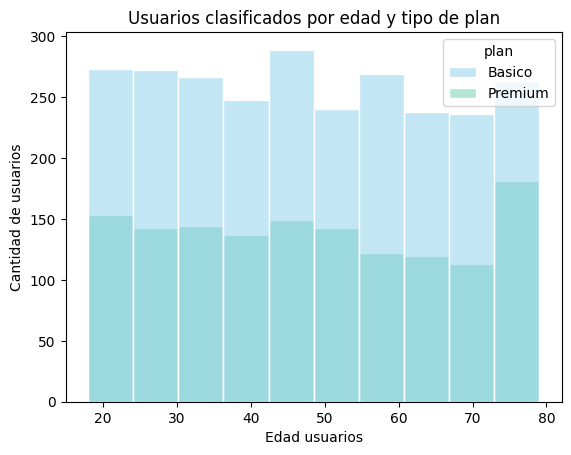

In [131]:
# Histograma para visualizar la edad (age)
sns.histplot(
    data=user_profile,
    x='age',
    bins=10,
    hue='plan',
    palette={'Basico': 'skyblue', 'Premium': 'mediumaquamarine'},
    edgecolor='white'
)

plt.xlabel('Edad usuarios')
plt.ylabel('Cantidad de usuarios')
plt.title('Usuarios clasificados por edad y tipo de plan')
plt.show()


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Histogramas completos: <code>hue='plan'</code>, colores diferenciados, título y etiquetas en ambos ejes.
</div>

💡Insights: 
- Las edades se distribuyen entre los distintos rangos y el plan Basico presenta más usuarios en términos absolutos. Para determinar si existe una mayor preferencia por Premium en edades avanzadas, es necesario comparar proporciones por rango de edad.

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Antes de afirmar que Premium aumenta entre los 74 y 79 años, ten en cuenta que en un histograma de conteos es difícil comparar los planes, porque hay casi el doble de clientes Básico. Verifícalo con proporciones, por ejemplo con <code>stat='density', common_norm=False</code> en <code>histplot</code>, o con <code>pd.crosstab(pd.cut(user_profile['age'], bins=[17,30,45,60,74,80]), user_profile['plan'], normalize='index')</code>. ¡Muy bien que lo planteas como algo a analizar con más detalle!
</div>

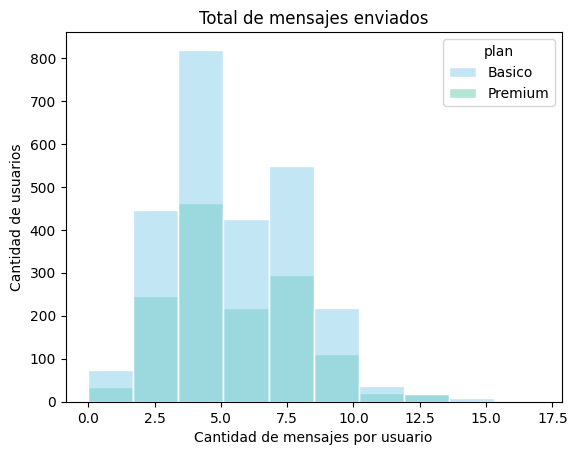

In [132]:
# Histograma para visualizar la cant_mensajes

sns.histplot(
    data=user_profile,
    x='cant_mensajes',
    bins=10,
    hue='plan',
    palette={'Basico': 'skyblue', 'Premium': 'mediumaquamarine'},
    edgecolor='white'
)
plt.xlabel('Cantidad de mensajes por usuario')
plt.ylabel('Cantidad de usuarios')
plt.title('Total de mensajes enviados')
plt.show()



💡Insights: 
- La mayor concentración de usuarios registra entre 2 y 9 mensajes, con una frecuencia máxima alrededor de 4 a 5 mensajes por usuario.
- El intervalo cercano a 4–5 mensajes presenta la frecuencia más alta.
- Hay pocos usuarios que envían más de 10 mensajes, lo que genera una *right skew distribution*.
- El plan Básico presenta más usuarios en prácticamente todos los intervalos, aunque se ve influenciado por la mayor cantidad de clientes con plan Básico contratado.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Muy buen insight! Rango, pico, sesgo a la derecha, y además reconoces que Básico tiene barras más altas por tener más clientes, no por enviar más mensajes.
</div>

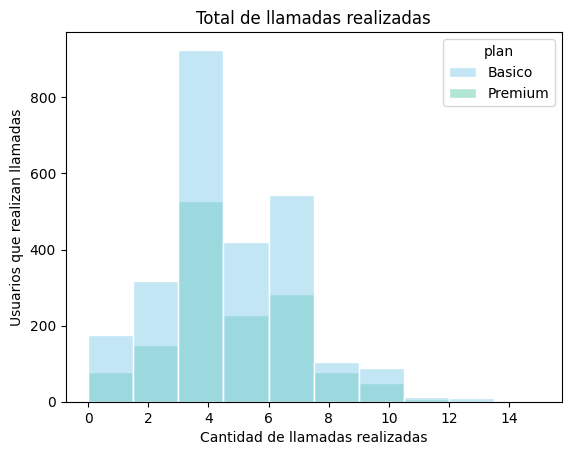

In [133]:
# Histograma para visualizar la cant_llamadas
sns.histplot(
    data=user_profile,
    x='cant_llamadas',
    bins=10,
    hue='plan',
    palette={'Basico': 'skyblue', 'Premium': 'mediumaquamarine'},
    edgecolor='white'
)
plt.xlabel('Cantidad de llamadas realizadas')
plt.ylabel('Usuarios que realizan llamadas')
plt.title('Total de llamadas realizadas')
plt.show()



💡Insights: 
- La mayor concentración de usuarios realiza entre 3 y 7 llamadas.
- La distribución presenta una *right skew distribution*, con una disminución en la frecuencia a partir de las 8 llamadas. Se identifican pocos usuarios que realizan más de 10 llamadas, lo que podría representar un segmento de mayor consumo.
- Ambos planes presentan patrones de uso similares, con una concentración de llamadas en los mismos intervalos. 

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Insight completo: rango, sesgo, posible segmento de mayor consumo y comparación entre planes.
</div>

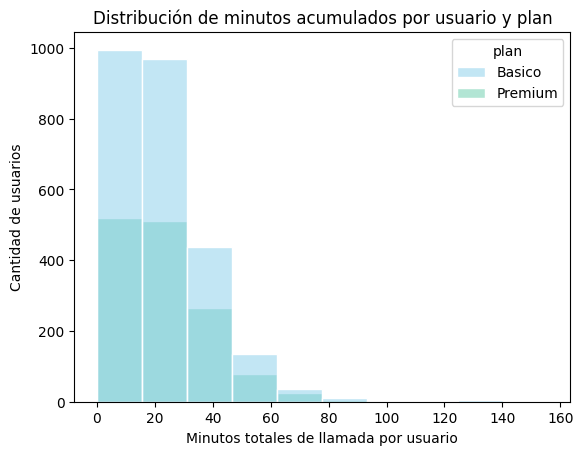

In [134]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(
    data=user_profile,
    x='cant_minutos_llamada',
    bins=10,
    hue='plan',
    palette={'Basico': 'skyblue', 'Premium': 'mediumaquamarine'},
    edgecolor='white'
)
plt.xlabel('Minutos totales de llamada por usuario')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución de minutos acumulados por usuario y plan')
plt.show()


💡Insights: 
- La mayoría de los usuarios acumula entre 0 y 40 minutos de llamadas, con una mayor concentración en los primeros 20 minutos.
- La distribución presenta uuna *right skew distribution*, con pocos usuarios que superan los 60 minutos, lo que podría indicar comportamientos de consumo atípicos.
- Ambos planes presentan patrones de consumo similares, aunque el plan Básico concentra una mayor cantidad de usuarios.
- El bajo consumo general de minutos podría representar una oportunidad para evaluar si los minutos incluidos en los planes se ajustan a las necesidades reales de los clientes.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Excelente: además de la forma y la comparación entre planes, conectas el bajo consumo con los minutos incluidos en los planes. Ese es un insight de negocio.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
En el gráfico, el eje Y dice "Minutos de llamada por usuario", pero muestra la <b>cantidad de usuarios</b>. Y el título habla de "duración de las llamadas" cuando la variable es el total de minutos por usuario.
</div>

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

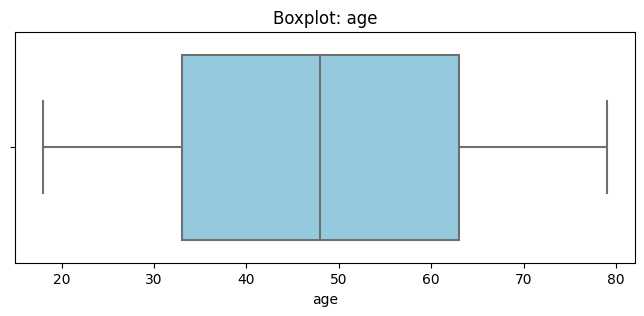

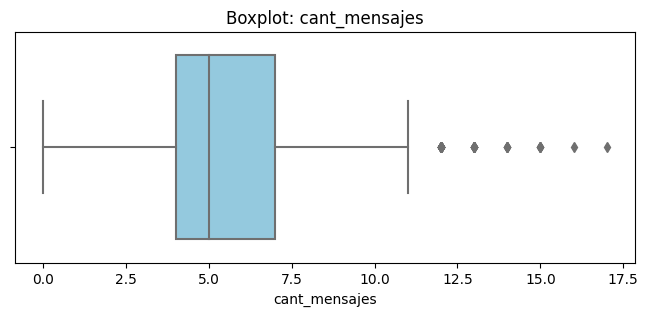

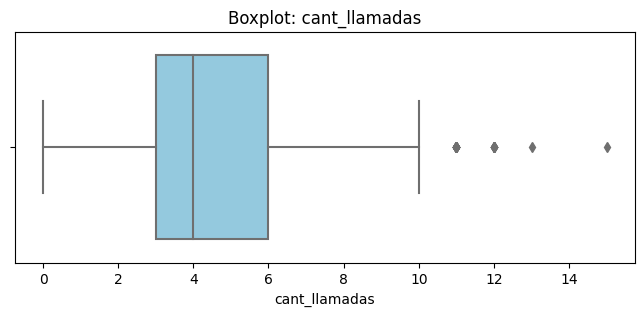

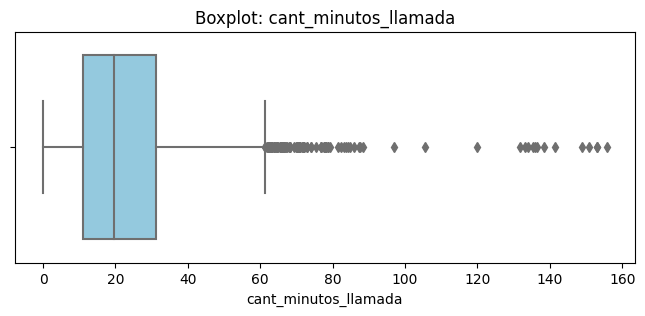

In [135]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=user_profile[col], color='skyblue')
    plt.title(f'Boxplot: {col}')


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Boxplots generados con un ciclo <code>for</code> y título dinámico, tal como se pedía.
</div>

💡Insights: 
- Age: No presenta outliers. Las edades se encuentran dentro de un rango esperado, entre 18 y 79 años.
- cant_mensajes: Presenta algunos valores atípicos superiores, correspondientes a usuarios que enviaron 12 o más mensajes.
- cant_llamadas: Presenta algunos valores atípicos superiores, correspondientes a usuarios que realizaron más de 10 llamadas.
- cant_minutos_llamada: Presenta bastantes valores atípicos, correspondientes a usuarios que acumularon más de 61.32 minutos de llamadas.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Interpretación precisa: indicas desde qué valor aparecen los outliers en cada variable.
</div>

In [136]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
for col in columnas_limites:
    print(col)
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    Limite_inferior = Q1 - 1.5 * IQR
    Limite_superior = Q3 + 1.5 * IQR
    outliers = user_profile.loc[
    (user_profile[col] < Limite_inferior) |
    (user_profile[col] > Limite_superior)]
    print('Límite inferior:', Limite_inferior)
    print('Límite superior:', Limite_superior)
    print('Cantidad de outliers:', len(outliers))
    print()


cant_mensajes
Límite inferior: -0.5
Límite superior: 11.5
Cantidad de outliers: 46

cant_llamadas
Límite inferior: -1.5
Límite superior: 10.5
Cantidad de outliers: 30

cant_minutos_llamada
Límite inferior: -19.055
Límite superior: 61.324999999999996
Cantidad de outliers: 96



<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Muy completo! Calculas ambos límites y cuántos usuarios son outliers en cada variable.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Los límites inferiores son negativos y no existen consumos negativos, así que aquí solo importa el límite superior (lo menciona la instrucción).
</div>

In [137]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,22.831225
std,2.359738,2.145139,16.592068
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.087500
50%,5.000000,4.000000,19.735000
75%,7.000000,6.000000,31.182500
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: Se identificaron 46 outliers (1.15%) que superan los 11.5 mensajes. Se recomienda conservarlos, ya que podrían representar usuarios con mayor actividad de mensajería.
- cant_llamadas: Se identificaron 30 outliers (0.75%) que superan las 10.5 llamadas. Se recomienda conservarlos, pues podrían corresponder a usuarios con un patrón de consumo elevado.
- cant_minutos_llamada: Se identificaron 96 outliers (2.40%) que superan los 61.32 minutos, alcanzando un máximo de 155.69 minutos. Se recomienda conservarlos, previa validación, ya que podrían representar usuarios con necesidades de consumo diferenciadas.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Decisión muy bien argumentada: cantidad y porcentaje de outliers, límite, máximo y por qué conservarlos.
</div>

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [138]:
# Crear columna grupo_uso
def segmentar(row):
    llamada = row['cant_llamadas']
    mensaje = row['cant_mensajes']

    if pd.isna(llamada) or pd.isna(mensaje):
        return "Error en datos"

    if llamada < 5 and mensaje < 5:
        return "Bajo uso"
    elif llamada < 10 and mensaje < 10:
        return "Uso medio"
    else:
        return "Alto uso"

user_profile['grupo_uso'] = user_profile.apply(segmentar, axis=1)


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Muy buena programación defensiva! Tu función detecta los nulos y los marca como "Error en datos" en lugar de clasificarlos mal. Además verificas el resultado con conteos y porcentajes.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
<code>apply(axis=1)</code> recorre las filas una por una y es lento con datasets grandes. La rúbrica sugiere <code>np.where</code> anidados, que son vectorizados y mucho más rápidos:<br><code>np.where(cond_bajo, 'Bajo uso', np.where(cond_medio, 'Uso medio', 'Alto uso'))</code>
</div>

In [139]:
# verificar cambios
print(user_profile['grupo_uso'].value_counts(normalize=True))
print()
print(user_profile['grupo_uso'].value_counts())

# Analizar los usuarios con minutos atípicos por segmento de uso
Q1 = user_profile['cant_minutos_llamada'].quantile(0.25)
Q3 = user_profile['cant_minutos_llamada'].quantile(0.75)
limite_superior = Q3 + 1.5 * (Q3 - Q1)

outliers_minutos = user_profile.loc[
    user_profile['cant_minutos_llamada'] > limite_superior
]
print()
print(outliers_minutos['grupo_uso'].value_counts())

user_profile.head()


Uso medio    0.73575
Bajo uso     0.19475
Alto uso     0.06950
Name: grupo_uso, dtype: float64

Uso medio    2943
Bajo uso      779
Alto uso      278
Name: grupo_uso, dtype: int64

Uso medio    70
Alto uso     23
Bajo uso      3
Name: grupo_uso, dtype: int64


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [140]:
# Crear columna grupo_edad
def segmentar_edad(row):
    edad = row['age']

    if pd.isna(edad):
        return "Error en datos"

    if edad < 30:
        return "Joven"
    elif edad < 60:
        return "Adulto"
    else:
        return "Adulto Mayor"

user_profile['grupo_edad'] = user_profile.apply(segmentar_edad, axis=1)

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Segmentación por edad correcta, con los cortes pedidos.
</div>

In [141]:
# verificar cambios
print(user_profile['grupo_edad'].value_counts(normalize=True))
print()
print(user_profile['grupo_edad'].value_counts())
user_profile.head()
print()


Adulto          0.5045
Adulto Mayor    0.3055
Joven           0.1900
Name: grupo_edad, dtype: float64

Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64



### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

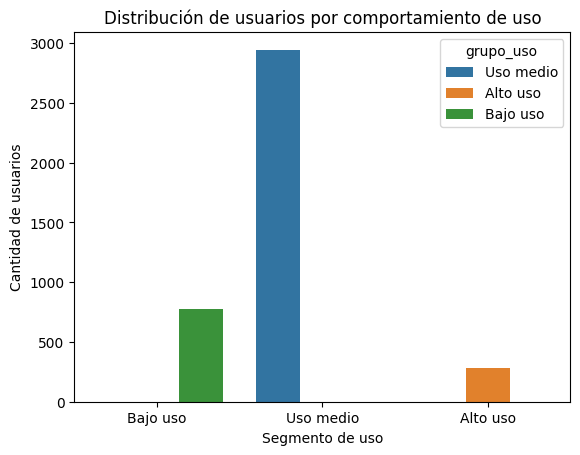

In [142]:
# Visualización de los segmentos por uso
sns.countplot(
    data=user_profile,
    x='grupo_uso',
    hue='grupo_uso',
    order=['Bajo uso', 'Uso medio', 'Alto uso']
)

plt.xlabel('Segmento de uso')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución de usuarios por comportamiento de uso')
plt.show()



<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Countplot con título, etiquetas en ambos ejes y categorías en orden lógico. Usar <code>hue</code> con la misma variable evita el aviso de seaborn al colorear por categoría. ¡Bien!
</div>

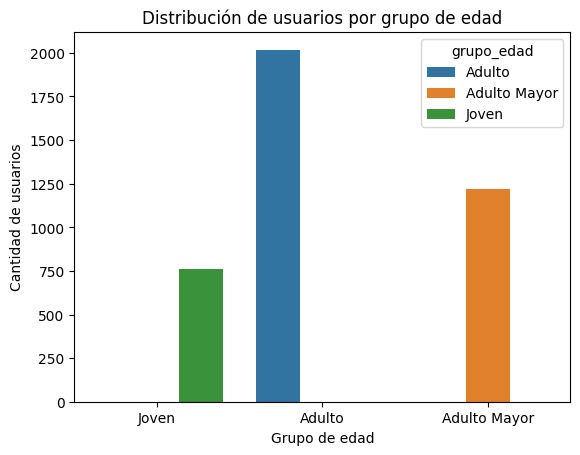

In [143]:
# Visualización de los segmentos por edad
sns.countplot(
    data=user_profile,
    x='grupo_edad',
    hue='grupo_edad',
    order=['Joven', 'Adulto', 'Adulto Mayor']
)

plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución de usuarios por grupo de edad')
plt.show()


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Gráfico de edad también ordenado y bien rotulado. Ambos countplots cumplen lo pedido.
</div>

In [144]:
# Promedio de consumo por grupo de edad
columnas_consumo = [
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

user_profile.groupby('grupo_edad')[columnas_consumo].mean().round(2)

,cant_mensajes,cant_llamadas,cant_minutos_llamada
grupo_edad,,,
Adulto,5.55,4.48,22.75
Adulto Mayor,5.49,4.50,22.79
Joven,5.52,4.43,23.12


In [145]:
# Promedio de consumo por plan
user_profile.groupby('plan')[columnas_consumo].mean().round(2)

,cant_mensajes,cant_llamadas,cant_minutos_llamada
plan,,,
Basico,5.53,4.45,22.57
Premium,5.52,4.52,23.31



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 


- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?
- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?
- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?


### Análisis ejecutivo

### 1. ⚠️ Problemas detectados en los datos

**¿Qué problemas tenían originalmente los datos? ¿Qué porcentaje o cantidad de filas representaban?**

- **Valores faltantes:** Se identificaron 3,534 valores nulos (88.35%) en `churn_date`, que podrían corresponder a usuarios activos, y 565 registros (14.13%) sin una ciudad identificable en `city`, considerando valores nulos y sentinels.
- **Valores inválidos:** Se detectaron 55 edades con el valor sentinel `-999` (1.38%), que fueron reemplazadas utilizando la mediana de las edades válidas (48 años). Asimismo, 40 fechas de registro correspondientes a 2026 (1%) fueron marcadas como nulas por encontrarse fuera del período de análisis.
- **Inconsistencias en el uso:** Se identificaron 28 registros (0.07%) con información en columnas que no corresponden a su tipo de actividad, además de 50 registros (0.125%) sin fecha en `usage`. Los nulos de `duration` y `length` asociados al tipo de actividad se conservaron por ser esperados.

### 2. 🔍 Segmentación de clientes por edad y nivel de uso

**¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?**

**Segmentos por edad:**

- **Jóvenes (menores de 30 años):** Representan el 19% de los clientes (760 usuarios), con un promedio de 5.52 mensajes, 4.43 llamadas y 23.12 minutos acumulados por usuario.
- **Adultos (30–59 años):** Constituyen el segmento más numeroso, con 2,018 usuarios (50.45%), y promedian 5.55 mensajes, 4.48 llamadas y 22.75 minutos.
- **Adultos mayores (60 años o más):** Representan el 30.55% de los clientes (1,222 usuarios), con promedios de 5.49 mensajes, 4.50 llamadas y 22.79 minutos.

Los tres grupos presentan patrones de consumo similares, lo que sugiere que la edad no genera diferencias importantes en el uso observado de llamadas y mensajes.

**Segmentos por nivel de uso:**

- **Bajo uso:** Representa el 19.48% de los clientes (779 usuarios), caracterizados por una baja actividad de llamadas y mensajes.
- **Uso medio:** Es el segmento predominante, con 2,943 usuarios (73.58%), lo que indica que la mayoría mantiene un consumo moderado.
- **Alto uso:** Comprende 278 usuarios (6.95%), que presentan una mayor actividad y podrían tener necesidades de consumo diferenciadas.

**Comparación por tipo de plan:**

El plan Basico concentra el 64.88% de los clientes y Premium el 35.12%. Sin embargo, ambos presentan promedios similares de consumo, cercanos a 5.5 mensajes, 4.5 llamadas y 23 minutos acumulados por usuario.

➡️ **Esto sugiere que** el nivel de consumo no está fuertemente diferenciado por edad ni por tipo de plan. Por lo tanto, segmentar a los clientes según sus hábitos de uso podría resultar más útil para identificar necesidades comerciales específicas.

### 3. ⭐ Segmentos más valiosos para ConnectaTel

**¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?**

- **Clientes Premium:** Representan un segmento importante por su mayor ingreso mensual contratado (USD 25 frente a USD 12 del plan Basico). Su retención podría contribuir a mantener los ingresos recurrentes de la empresa. Sin embargo, sería necesario evaluar costos y rentabilidad para determinar su valor económico real.
- **Usuarios de alto consumo:** Aunque representan solamente el 6.95% de los clientes, podrían generar oportunidades comerciales mediante paquetes adicionales de llamadas o mensajes y planes adaptados a sus necesidades.
- **Usuarios de uso medio:** Constituyen el segmento más relevante por volumen, al representar el 73.58% de la base de clientes. Las mejoras en su experiencia y satisfacción podrían tener un impacto importante en la retención general.

➡️ **Esto sugiere que** ConnectaTel debe priorizar la fidelización de clientes Premium por su mayor ingreso contratado, analizar oportunidades de venta adicional entre usuarios de alto consumo y mantener una oferta competitiva para el segmento de uso medio, que concentra la mayoría de sus clientes.

### 4. 📊 Patrones de uso extremo (outliers)

**¿Qué patrones de uso extremo encontraste y qué implican para el negocio?**

Mediante el método IQR se identificaron los siguientes valores atípicos:

- **Cantidad de mensajes:** 46 usuarios (1.15%) registraron más de 11.5 mensajes, alcanzando un máximo de 17.
- **Cantidad de llamadas:** 30 usuarios (0.75%) realizaron más de 10.5 llamadas, con un máximo de 15.
- **Minutos de llamadas:** 96 usuarios (2.40%) superaron los 61.32 minutos acumulados, alcanzando un máximo de 155.69 minutos.

Los valores atípicos se conservaron, ya que podrían representar comportamientos reales de mayor consumo y no necesariamente errores en los datos.

Un hallazgo relevante es que 70 de los 96 usuarios con minutos atípicos pertenecen al segmento de uso medio. Esto indica que algunos clientes pueden realizar una cantidad moderada de llamadas, pero acumular una duración significativamente mayor.

➡️ **Esto sugiere que** la cantidad de llamadas y mensajes no siempre refleja completamente las necesidades de consumo. Incorporar la duración de las llamadas permitiría identificar mejor a los usuarios con patrones de uso diferenciados y desarrollar ofertas comerciales más precisas.

### 5. 💡 Recomendaciones comerciales

**¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?**

1. **Optimizar los planes actuales:** Evaluar si los beneficios de los planes Basico y Premium corresponden al consumo real de los usuarios, considerando que ambos presentan patrones similares de llamadas y mensajes. También sería importante analizar si los datos móviles incluidos (GB) influyen en la elección de cada plan.

2. **Diseñar alternativas para usuarios de bajo consumo:** Evaluar planes más económicos o con menores cantidades incluidas de llamadas y mensajes para atender al 19.48% de los clientes que presentan baja actividad, buscando mejorar la adecuación de la oferta a sus necesidades.

3. **Desarrollar paquetes adicionales para usuarios de alto consumo:** Ofrecer opciones con mayores beneficios de llamadas o mensajes para los clientes que superan los niveles habituales, generando oportunidades de ingresos adicionales.

4. **Incorporar la duración en la segmentación comercial:** Considerar los minutos acumulados además de la cantidad de llamadas, ya que se identificaron usuarios con una frecuencia moderada de llamadas, pero con una duración elevada. Esto permitiría crear paquetes específicos de minutos.

5. **Fortalecer la retención de clientes Premium:** Investigar los factores que motivan la contratación de este plan y evaluar su satisfacción, con el objetivo de ofrecer beneficios diferenciados y reducir posibles cancelaciones.

6. **Profundizar el análisis antes de modificar precios:** Comparar el consumo mensual con los beneficios incluidos en cada plan, incorporar el uso de datos móviles y analizar indicadores financieros y de cancelación para determinar la viabilidad y rentabilidad de las propuestas.

### ✅ Conclusión general

El análisis permitió identificar que la mayoría de los clientes de ConnectaTel mantiene un nivel de uso medio y que los patrones de consumo son relativamente similares entre grupos de edad y tipos de plan.

Las principales oportunidades comerciales se encuentran en fortalecer la retención de los clientes Premium, mejorar la oferta para el segmento mayoritario de uso medio y desarrollar alternativas para usuarios con necesidades de consumo diferenciadas.

Asimismo, los valores atípicos muestran la importancia de considerar tanto la frecuencia como la duración de las llamadas para comprender mejor el comportamiento de los clientes.

Finalmente, se recomienda complementar el análisis con información mensual de consumo, datos móviles e indicadores de rentabilidad antes de implementar cambios en los planes comerciales.


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Muy buen análisis ejecutivo! Cuantificas cada problema con cantidad y porcentaje (incluidos los 28 registros inconsistentes), describes cada segmento con su tamaño y llegas a una conclusión muy valiosa: Premium no se asocia a mayor consumo y el comportamiento es homogéneo entre edades y planes.
</div>

<div class="alert alert-block alert-danger">
<b>❌ Comentario del revisor. (Iteración 1) — Necesita arreglos</b> <a class="tocSkip"></a><br>
Quedaron dos preguntas del paso 7 sin contestar:
<ul>
<li><b>Recomendaciones:</b> falta la sección. Tienes ideas dispersas en tus insights (planes de menor capacidad para el bajo uso, planes especializados para el alto uso, revisar si los minutos incluidos se ajustan al consumo real); reúnelas en una sección de recomendaciones concretas para mejorar la oferta o crear nuevos planes.</li>
<li><b>Segmentos más valiosos:</b> ¿cuáles son para ConnectaTel y por qué?</li>
</ul>
Un detalle adicional: los promedios por grupo de edad que citas (5.5 mensajes, 4.5 llamadas, 23 minutos) no aparecen en ninguna salida del notebook. Agrega un <code>user_profile.groupby('grupo_edad')[columnas].mean()</code> para respaldarlos.
</div>

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.

Link a repositorio público del proyecto: https://github.com/marcelaenrigue/sprint7-final-project

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Escribe el link en esta celda Markdown, reemplazando el texto de la plantilla <code>`LINK a tu repo aquí`</code>.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
El link quedó en una celda de <b>código</b>: al ejecutar todo el notebook, esta celda produce un <code>SyntaxError</code>. Muévelo a la celda Markdown de arriba y elimina esta celda. Asegúrate también de que el repositorio tenga el notebook y un <code>README.md</code> con objetivo, datasets, etapas del análisis y cómo ejecutarlo.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
<b>📊 Evaluación según la rúbrica DA Sprint 7</b><br><table><tr><th>Parte</th><th>Criterio</th><th>Estado</th></tr><tr><td>1. Carga y exploración</td><td>Librerías, carga, head/info/shape</td><td>✅</td></tr><tr><td>2. Calidad de datos</td><td>Nulos (conteo y proporción)</td><td>✅</td></tr><tr><td></td><td>Sentinels (-999 y "?")</td><td>✅</td></tr><tr><td></td><td>Fechas (errors='coerce', .dt.year)</td><td>✅</td></tr><tr><td></td><td>Diagnóstico escrito</td><td>✅</td></tr><tr><td>3. Limpieza</td><td>Mediana en age + validación</td><td>✅ (sugerencia: excluir sentinel)</td></tr><tr><td></td><td>"?" → pd.NA</td><td>🟡 reemplazado por el texto "NA"</td></tr><tr><td></td><td>Fechas imposibles → nulo</td><td>✅</td></tr><tr><td></td><td>Evaluación MAR</td><td>✅</td></tr><tr><td></td><td>Decisión justificada</td><td>🟡 etiquetado como MNAR</td></tr><tr><td>4. Uso por usuario</td><td>Agrupación, métricas y merge</td><td>✅ (sugerencia: fillna(0))</td></tr><tr><td></td><td>Revisión estadística</td><td>🟡 falta interpretación escrita</td></tr><tr><td>5. Distribuciones y outliers</td><td>Histogramas con hue</td><td>✅</td></tr><tr><td></td><td>Interpretación</td><td>✅</td></tr><tr><td></td><td>Boxplots e IQR</td><td>✅</td></tr><tr><td>6. Segmentación</td><td>grupo_uso / grupo_edad</td><td>✅</td></tr><tr><td></td><td>Countplots rotulados</td><td>✅</td></tr><tr><td>7. Insight ejecutivo</td><td>Segmentos y comportamiento</td><td>✅</td></tr><tr><td></td><td>Segmentos valiosos</td><td>❌ sin contestar</td></tr><tr><td></td><td>Recomendaciones</td><td>❌ sección ausente</td></tr><tr><td>8. Publicación</td><td>Link al repositorio</td><td>🟡 en celda de código</td></tr></table><br>Criterios en ❌ (paso 7) → <b>proyecto devuelto para una nueva iteración</b>.
</div>

<div class="alert alert-block alert-info">
<b>Comentario del revisor. (Iteración 1) — Próximos pasos</b> <a class="tocSkip"></a><br><br>
Marcela, tu proyecto tiene un nivel de análisis sobresaliente y está a un paso de la aprobación. Para la siguiente iteración, el único punto bloqueante ❌ es:
<ol><li><b>Análisis ejecutivo (paso 7):</b> agregar la sección de <b>recomendaciones</b> y responder qué <b>segmentos son más valiosos</b> y por qué.</li></ol>
En la siguiente iteración revisaré únicamente este punto, así que no habrá requisitos nuevos. Las recomendaciones 🟡 son opcionales, aunque te sugiero especialmente reemplazar el <code>"?"</code> por un nulo real, corregir la etiqueta MAR/MNAR y mover el link a la celda Markdown.<br><br>
¡Ánimo, ya casi está! 💪
</div>